# Iris species classification
Datheon internship · Task 1

Can four flower measurements distinguish setosa, versicolor and virginica? We compare Logistic Regression and a Decision Tree on the same held-out flowers.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

seed = 42
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
names = iris.target_names
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=seed
)
print("Training flowers:", len(X_train), "| Test flowers:", len(X_test))
print("Missing measurements:", X.isna().sum().sum())
print(pd.crosstab(y.map(dict(enumerate(names))), np.where(X.index.isin(X_train.index), "Train", "Test")))

Training flowers: 120 | Test flowers: 30
Missing measurements: 0
col_0       Test  Train
target                 
setosa        10     40
versicolor    10     40
virginica     10     40


## Explore the training flowers
Each point represents a flower. The diagonal histograms show how individual measurements vary within each species. Look at petal length and width to see where the groups overlap.

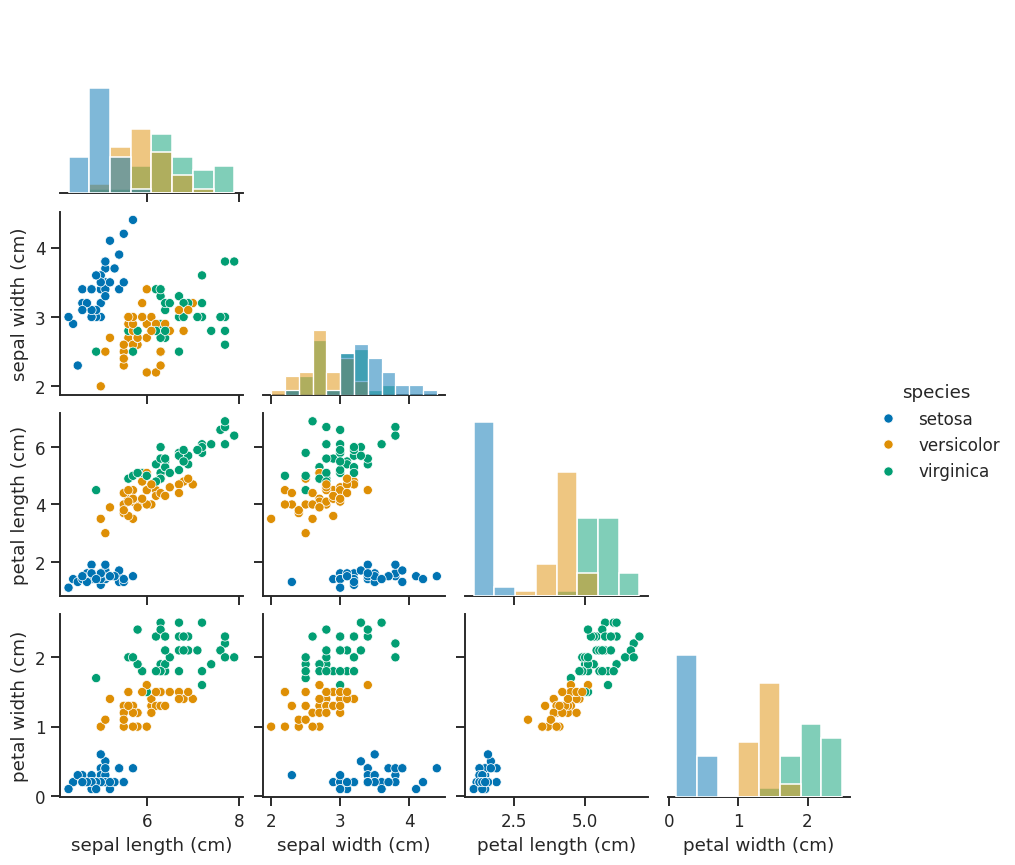

In [2]:
sns.set_theme(style="ticks")
training = X_train.assign(species=y_train.map(dict(enumerate(names))))
g = sns.pairplot(training, hue="species", hue_order=list(names), diag_kind="hist",
                 corner=True, height=2, palette="colorblind")
plt.show()

## Train and evaluate
Each pipeline learns its scaling parameters from the training rows. Both models use all four features. Accuracy counts correct predictions overall. Macro precision, recall and F1 give each species equal weight.

In [3]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=seed))
}
scores = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    report = classification_report(y_test, predicted, target_names=names, output_dict=True)
    scores.append({"Model": name, "Accuracy": accuracy_score(y_test, predicted),
                   **{k: report["macro avg"][k] for k in ("precision", "recall", "f1-score")}})
    print(name)
    print(classification_report(y_test, predicted, target_names=names, digits=3))
print(pd.DataFrame(scores).set_index("Model").round(4))

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

                     Accuracy  precision  recall  f1-score
Model                                                     
Logistic Regression    0.9333     0.9333  0.9333    0.9333
Decision Tree          0.93

## Confusion matrices
Read across each actual species. Diagonal cells count correct predictions. Off-diagonal cells identify which flowers the model confused.

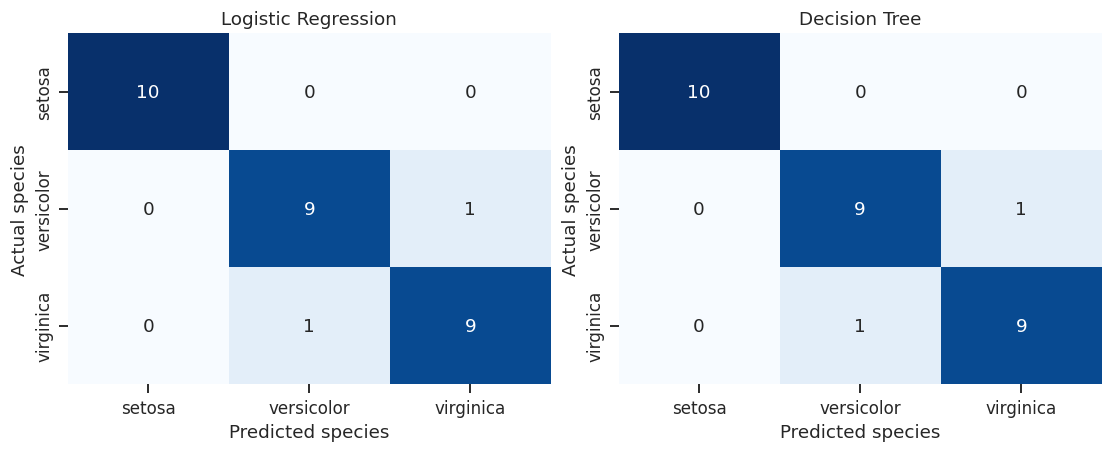

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, (name, predicted) in zip(axes, predictions.items()):
    counts = confusion_matrix(y_test, predicted, labels=range(len(names)))
    sns.heatmap(counts, annot=True, fmt="d", vmin=0, vmax=10, cmap="Blues",
                xticklabels=names, yticklabels=names, cbar=False, ax=ax)
    ax.set(title=name, xlabel="Predicted species", ylabel="Actual species")
plt.show()

## Decision regions using two measurements
For this illustration we refit each classifier on training petal length and width only. Background colors show model predictions at each coordinate. Dots show the true species of held-out flowers. The reports above evaluate the four-feature models.

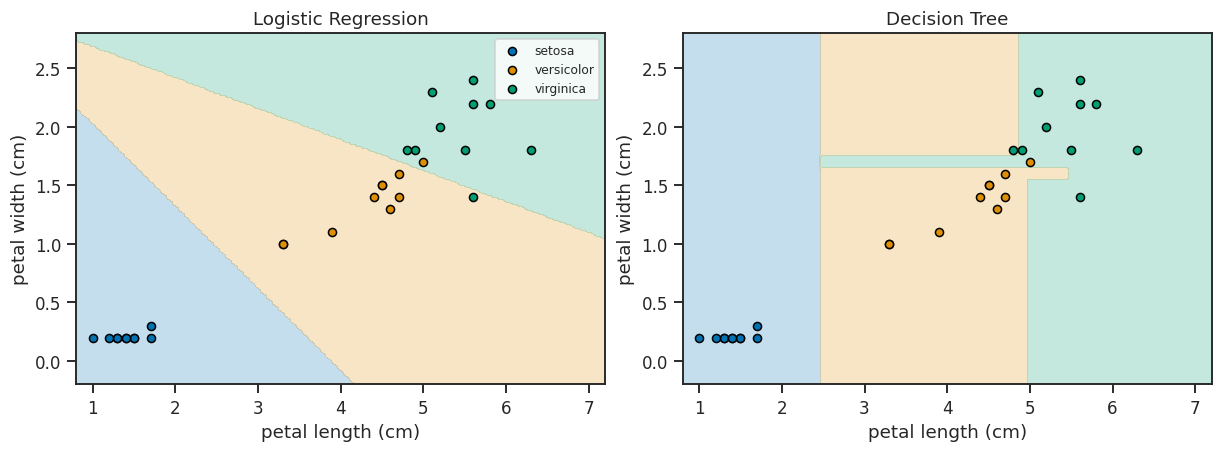

In [5]:
from sklearn.base import clone

features = ["petal length (cm)", "petal width (cm)"]
petals = X_train[features]
grid_axes = [np.linspace(petals[col].min() - 0.3, petals[col].max() + 0.3, 180)
             for col in features]
xx, yy = np.meshgrid(*grid_axes)
grid = pd.DataFrame({features[0]: xx.ravel(), features[1]: yy.ravel()})
colors = sns.color_palette("colorblind", 3)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, (name, model) in zip(axes, models.items()):
    visual_model = clone(model).fit(petals, y_train)
    regions = visual_model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, regions, levels=[-0.5, 0.5, 1.5, 2.5],
                cmap=ListedColormap(colors), alpha=0.23)
    for label, species in enumerate(names):
        points = X_test.loc[y_test == label, features]
        ax.scatter(points.iloc[:, 0], points.iloc[:, 1], color=colors[label],
                   edgecolors="black", label=species, s=28)
    ax.set(title=name, xlabel=features[0], ylabel=features[1])
axes[0].legend(fontsize=8)
plt.show()

## Interpretation
On this split the accuracy scores correspond to Logistic Regression getting 28 of 30 correct and Decision Tree getting 28 of 30 correct. A single flower changes accuracy by about 3.3 percentage points. Repeated stratified cross-validation would help assess how sensitive this comparison is to the split.